# ML MODEL

## Import libraries

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import to_timestamp, month, dayofmonth, hour, dayofweek, col, expr, when
from pyspark.ml.feature import StringIndexer
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


## Creating Spark session 

In [2]:
# Create a SparkSession
spark = SparkSession.builder.appName("ChicahoCrime").config("spark.driver.memory", "8g").getOrCreate()

# Load Excel file
file_path = "part.csv"

df = spark.read.csv(f"{file_path}", header=True, inferSchema=True)
df.show(5)


+--------+-----------+----------------+--------------------+----+--------------+--------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+----------------+------------+-------------+--------------------+
|      id|case number|            date|               block|iucr|  primary type|         description|location description|arrest|domestic|beat|district|ward|community area|fbi code|x coordinate|y coordinate|year|      updated on|    latitude|    longitude|            location|
+--------+-----------+----------------+--------------------+----+--------------+--------------------+--------------------+------+--------+----+--------+----+--------------+--------+------------+------------+----+----------------+------------+-------------+--------------------+
|13709672|   JJ101940|31/12/2024 23:58|     014XX E 68TH ST|1310|PROPERTY CRIME|         TO PROPERTY|         RESIDENTIAL| false|   false| 332|       3|   5|         

In [3]:
# Convert 'Date' string column to timestamp using correct format
df = df.withColumn("date", to_timestamp("date", "dd/MM/yyyy HH:mm"))

# Extract time-based features
df = df.withColumn("month", month("date")) \
       .withColumn("day", dayofmonth("date")) \
       .withColumn("hour", hour("date")) \
       .withColumn("day_of_week", dayofweek("date"))

# Show the new columns
df.select("date", "month", "day", "hour", "day_of_week").show(5)


+-------------------+-----+---+----+-----------+
|               date|month|day|hour|day_of_week|
+-------------------+-----+---+----+-----------+
|2024-12-31 23:58:00|   12| 31|  23|          3|
|2024-12-31 23:56:00|   12| 31|  23|          3|
|2024-12-31 23:55:00|   12| 31|  23|          3|
|2024-12-31 23:53:00|   12| 31|  23|          3|
|2024-12-31 23:50:00|   12| 31|  23|          3|
+-------------------+-----+---+----+-----------+
only showing top 5 rows



In [4]:
# Apply StringIndexer 
indexer_primary_type = StringIndexer(inputCol="primary type", outputCol="primary_type_index", handleInvalid="keep")
indexer_description = StringIndexer(inputCol="description", outputCol="description_index", handleInvalid="keep")
indexer_location = StringIndexer(inputCol="location description", outputCol="location_description_index", handleInvalid="keep")

'''
# no need to transform since we use pipeline
Fit and transform each indexer on the DataFrame
df = indexer_primary_type.fit(df).transform(df)
df = indexer_description.fit(df).transform(df)
df = indexer_location.fit(df).transform(df)
'''
# Step 3: Verify the result
#df.select("primary type", "primary_type_index", "description", "description_index", "location description", "location_description_index").show(5, truncate=False)


'\n# Step 2: Fit and transform each indexer on the DataFrame\ndf = indexer_primary_type.fit(df).transform(df)\ndf = indexer_description.fit(df).transform(df)\ndf = indexer_location.fit(df).transform(df)\n'

## Assemble Features

In [5]:
assembler = VectorAssembler(
    inputCols=[
        "description_index", "location_description_index", "domestic", "arrest",
        "x coordinate", "y coordinate",
        "month", "day", "hour", "day_of_week",
        "beat","district","ward","community area"
    ],
    outputCol="features"
)


## Define classifier and pipeline

In [6]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="primary_type_index",
    numTrees=10,
    maxDepth=10,
    maxBins=550
)

pipeline = Pipeline(stages=[indexer_primary_type, indexer_location, indexer_description, assembler, rf])


# Train/test split
train_data, test_data = df.randomSplit([0.8, 0.2], seed=42)
train_sample = train_data.sample(0.3, seed=42).cache()


## Start Training

In [7]:
model = pipeline.fit(train_sample)

## Evaluate with test set

In [8]:
predictions = model.transform(test_data)

evaluator = MulticlassClassificationEvaluator(
    labelCol="primary_type_index", 
    predictionCol="prediction", 
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)
print(f"Test Set Accuracy = {accuracy}")


Test Set Accuracy = 0.8540676159324246


## Confusion Matrix

In [9]:
# Generate predictions
predictions = model.transform(test_data)

# Select actual vs predicted
confusion_df = predictions.select("primary_type_index", "prediction")

# Create confusion matrix
conf_matrix = confusion_df.groupBy("primary_type_index").pivot("prediction").count().na.fill(0)

conf_matrix.show()


+------------------+------+------+-----+-----+-----+----+---+
|primary_type_index|   0.0|   1.0|  2.0|  3.0|  4.0| 5.0|6.0|
+------------------+------+------+-----+-----+-----+----+---+
|               0.0|214607|  7909| 2963|  320| 1535|  61|  0|
|               1.0|  6182|140815| 2325|  390| 4127| 255|  0|
|               4.0|   125|   498|   10|    0|19236| 269|  0|
|               3.0|  5456|  4213| 2746|14503| 4279| 175|  1|
|               2.0|  3223|  4883|26195|  386|  905|  58|  0|
|               6.0|  1110|  2103| 1564|   88| 1407|  35| 17|
|               5.0|  1144|  4107|  599|   88| 6469|6053|  0|
+------------------+------+------+-----+-----+-----+----+---+



In [10]:
# Convert Spark DataFrame to Pandas
conf_matrix_pd = conf_matrix.toPandas()

# Set index to the actual class (Primary_Type_index)
conf_matrix_pd.set_index("primary_type_index", inplace=True)

# Sort both axes just in case
conf_matrix_pd = conf_matrix_pd.sort_index(axis=0).sort_index(axis=1)


## plot confusion matrix

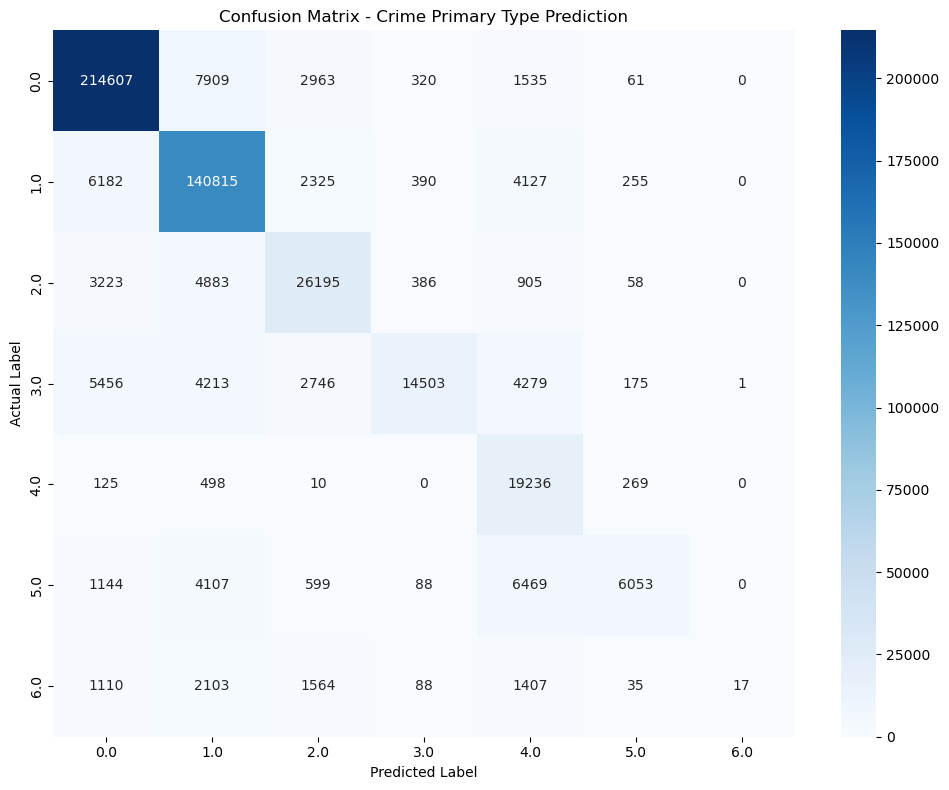

In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_pd, annot=True, fmt="d", cmap="Blues", cbar=True)

plt.title("Confusion Matrix - Crime Primary Type Prediction")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# OPTIMIZATION

## Feature importance

In [12]:
# Get feature importances from the trained model (last stage in your pipeline)
rf_model = model.stages[-1]
importances = rf_model.featureImportances.toArray()


In [13]:
# Get feature column names used in the VectorAssembler
assembler_stage = [stage for stage in model.stages if isinstance(stage, VectorAssembler)][0]
feature_names = assembler_stage.getInputCols()


In [14]:
import pandas as pd

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)


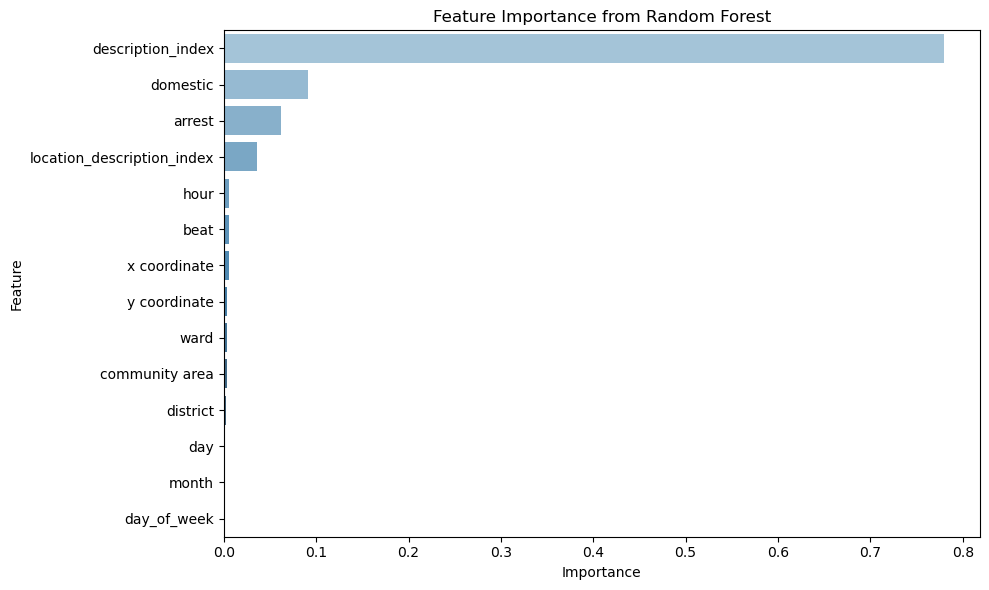

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df, x="Importance", y="Feature", palette="Blues_d")
plt.title("Feature Importance from Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


##  Drop Low-Importance Features

In [20]:
# New reduced feature list (excluding low-importance features)
reduced_features = [
    'description_index',
    'arrest',
    'domestic',
    'location_description_index',
    'beat',
    'hour'
]


## Create assembler with new features

In [21]:
assembler = VectorAssembler(inputCols=reduced_features, outputCol="features")

## setup cross-validation and gridsearch()

In [24]:
# Define the classifier again
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="primary_type_index"
)

# Build param grid
paramGrid = (ParamGridBuilder()
             .addGrid(rf.numTrees, [10, 50])
             .addGrid(rf.maxDepth, [5, 10])
             .addGrid(rf.maxBins, [1024]) 
             .build())


# Evaluator
evaluator = MulticlassClassificationEvaluator(
    labelCol="primary_type_index",
    predictionCol="prediction",
    metricName="accuracy"
)

# CrossValidator setup
crossval = CrossValidator(
    estimator=rf,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    numFolds=3
)

# Update your pipeline
pipeline = Pipeline(stages=[indexer_primary_type, indexer_location, indexer_description, assembler, crossval])


In [25]:
# Fit model
cv_model = pipeline.fit(train_data)

## Print Evaluation Metrics

In [26]:
# Predict and evaluate
predictions = cv_model.transform(test_data)
accuracy = evaluator.evaluate(predictions)
print(f"Cross-Validated Test Accuracy: {accuracy:.4f}")


Cross-Validated Test Accuracy: 0.8909


In [27]:
evaluator.setMetricName("weightedPrecision")
precision = evaluator.evaluate(predictions)
print(f"Weighted Precision: {precision:.4f}")


Weighted Precision: 0.9157


In [28]:
evaluator.setMetricName("weightedRecall")
recall = evaluator.evaluate(predictions)
print(f"Weighted Recall: {recall:.4f}")


Weighted Recall: 0.8909


In [29]:
evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)
print(f"Weighted F1 Score: {f1_score:.4f}")


Weighted F1 Score: 0.8884


## Extract best parameters

In [30]:
# Extract the CrossValidatorModel from the fitted pipeline
cv_model_stage = cv_model.stages[-1]  # This is the CrossValidatorModel

# Extract the best RandomForestClassificationModel
best_rf_model = cv_model_stage.bestModel  # This is the best RF model

# Print the best parameters
print(f"Best Number of Trees: {best_rf_model.getNumTrees}")
print(f"Best Max Depth: {best_rf_model.getOrDefault('maxDepth')}")
print(f"Best Max Bins: {best_rf_model.getOrDefault('maxBins')}")


Best Number of Trees: 10
Best Max Depth: 10
Best Max Bins: 1024


## Evaluate Class-Wise Precision, Recall, F1 Score

In [31]:
from pyspark.sql.functions import col, expr, when

# Create TP, FP, FN for each label
metrics_df = predictions.select("primary_type_index", "prediction") \
    .withColumn("TP", when(col("primary_type_index") == col("prediction"), 1).otherwise(0)) \
    .withColumn("FP", when(col("primary_type_index") != col("prediction"), 1).otherwise(0)) \
    .withColumn("FN", when(col("primary_type_index") != col("prediction"), 1).otherwise(0))

# Group by actual class
summary = metrics_df.groupBy("primary_type_index") \
    .agg(
        expr("sum(TP) as TP"),
        expr("sum(FP) as FP"),
        expr("sum(FN) as FN"),
        expr("count(*) as total")
    )

# Calculate precision, recall, F1-score
summary = summary.withColumn("precision", col("TP") / (col("TP") + col("FP"))) \
                 .withColumn("recall", col("TP") / (col("TP") + col("FN"))) \
                 .withColumn("f1_score", 2 * (col("precision") * col("recall")) / (col("precision") + col("recall")))

summary.select("primary_type_index", "precision", "recall", "f1_score").show(truncate=False)


+------------------+--------------------+--------------------+--------------------+
|primary_type_index|precision           |recall              |f1_score            |
+------------------+--------------------+--------------------+--------------------+
|0.0               |0.9337408474240858  |0.9337408474240858  |0.9337408474240858  |
|1.0               |0.9461497527483225  |0.9461497527483225  |0.9461497527483225  |
|4.0               |0.9910616744463204  |0.9910616744463204  |0.9910616744463204  |
|3.0               |0.6725528320530393  |0.6725528320530393  |0.6725528320530393  |
|2.0               |0.8672089761570827  |0.8672089761570827  |0.8672089761570828  |
|6.0               |0.023244781783681213|0.023244781783681213|0.023244781783681213|
|5.0               |0.5076923076923077  |0.5076923076923077  |0.5076923076923077  |
+------------------+--------------------+--------------------+--------------------+



In [32]:
# You must use the fitted StringIndexerModel from training
label_mapping = indexer_primary_type.fit(df).labels

# Example: Print label name for each index
for i, label in enumerate(label_mapping):
    print(f"Index {i} = {label}")


Index 0 = PROPERTY CRIME
Index 1 = VIOLENT CRIME
Index 2 = WHITE-COLLAR/REGULATORY
Index 3 = OTHER OFFENSE
Index 4 = DRUG RELATED
Index 5 = PUBLIC ORDER
Index 6 = SEXUAL CRIME
